# Phase 6 — Part 3B: GPU sweetness attribute volumes
Run once after Part 1. Computes sweetness from matched baseline/monitor, then 10-ms sampled with 50% overlapping ±10 ms windows volumes. Uses the same trace order as Part 1.

**Storage configuration (quota-safe):** Read-only SEG-Y checkpoints remain in `/home/apgce_team_08/Phase6_Checkpoints`; all shared float32 caches go to `/data/epic20/APGCE/phase6_shared_cache`; RMS/sweetness `.npy` arrays go to `/data/epic20/APGCE/phase6_attributes/Attributes_10ms_50pct_overlap`; Part 3C horizon exports/QC go to `/data/epic20/APGCE/phase6_horizons`. Confirm writable project quota before executing. **Do not run 3A and 3B simultaneously on first cache creation.**


In [1]:

# Reusable Phase 6 SEG-Y checkpoint I/O: writes IEEE float32 with baseline headers.
import numpy as np, pandas as pd, segyio, json
from pathlib import Path
CHECKPOINT_ROOT=Path('/home/apgce_team_08/Phase6_Checkpoints')
# Checkpoint inputs are read-only; never create files in the home checkpoint directory
def export_segy(path, data, geometry, reference_path, reference_indices=None, batch=128):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    geometry=geometry.reset_index(drop=True)
    if data.shape[0]!=len(geometry):raise ValueError('Trace geometry mismatch')
    if not np.isfinite(geometry[['X','Y']].to_numpy()).all():
        raise ValueError('Invalid X/Y; cannot write reliable SEG-Y geometry')
    tmp=path.with_suffix('.partial.sgy')
    if tmp.exists():tmp.unlink()
    with segyio.open(str(reference_path),'r',ignore_geometry=True) as src:
        if reference_indices is None:
            if src.tracecount!=len(geometry):raise ValueError('Reference trace count differs')
            reference_indices=np.arange(len(geometry))
        if len(src.samples)!=data.shape[1]:raise ValueError('Reference sample axis differs')
        spec=segyio.spec(); spec.tracecount=len(geometry)
        spec.samples=src.samples; spec.format=5
        with segyio.create(str(tmp),spec) as dst:
            dst.bin=src.bin; dst.bin[segyio.BinField.Format]=5
            dst.text[0]=src.text[0]
            for i in range(len(geometry)):
                header=dict(src.header[int(reference_indices[i])]); g=geometry.iloc[i]
                header[segyio.TraceField.INLINE_3D]=int(g.Inline)
                header[segyio.TraceField.CROSSLINE_3D]=int(g.Crossline)
                scalar=int(header.get(segyio.TraceField.SourceGroupScalar,1))
                if scalar==0:scalar=1;header[segyio.TraceField.SourceGroupScalar]=1
                factor=scalar if scalar>0 else 1/abs(scalar)
                header[segyio.TraceField.CDP_X]=int(round(float(g.X)/factor))
                header[segyio.TraceField.CDP_Y]=int(round(float(g.Y)/factor))
                dst.header[i]=header
                dst.trace[i]=np.asarray(data[i],dtype=np.float32)
                if (i+1)%100000==0:print(path.name,i+1,'/',len(geometry))
            dst.flush()
    with segyio.open(str(tmp),'r',ignore_geometry=True) as check:
        if check.tracecount!=len(geometry) or len(check.samples)!=data.shape[1]:
            raise RuntimeError('Written SEG-Y dimensions failed QC')
        if check.bin[segyio.BinField.Format]!=5:raise RuntimeError('Output not IEEE float32')
        test=np.unique(np.linspace(0,len(geometry)-1,min(20,len(geometry)),dtype=int))
        for i in test:
            h=check.header[int(i)]
            if (int(h[segyio.TraceField.INLINE_3D])!=int(geometry.iloc[i].Inline) or
                int(h[segyio.TraceField.CROSSLINE_3D])!=int(geometry.iloc[i].Crossline)):
                raise RuntimeError('SEG-Y trace-order QC failed')
            scalar=int(h[segyio.TraceField.SourceGroupScalar]);factor=scalar if scalar>0 else (1/abs(scalar) if scalar<0 else 1)
            if abs(h[segyio.TraceField.CDP_X]*factor-float(geometry.iloc[i].X))>max(.01,abs(factor)/2+.01):
                raise RuntimeError('SEG-Y X coordinate QC failed')
    tmp.replace(path)
    print('Verified:',path)

def load_checkpoint(path,cache_dir):
    path=Path(path);cache_dir=Path(cache_dir);cache_dir.mkdir(parents=True,exist_ok=True)
    if not path.exists():raise FileNotFoundError(f'Missing checkpoint: {path}; run previous stage')
    with segyio.open(str(path),'r',ignore_geometry=True) as f:
        n,ns=f.tracecount,len(f.samples);samples=np.asarray(f.samples,dtype=np.float64)
        dt=float(f.bin[segyio.BinField.Interval])/1000
        il=np.asarray(f.attributes(segyio.TraceField.INLINE_3D)[:],dtype=np.int32)
        xl=np.asarray(f.attributes(segyio.TraceField.CROSSLINE_3D)[:],dtype=np.int32)
        xr=np.asarray(f.attributes(segyio.TraceField.CDP_X)[:],dtype=np.float64)
        yr=np.asarray(f.attributes(segyio.TraceField.CDP_Y)[:],dtype=np.float64)
        scalar=np.asarray(f.attributes(segyio.TraceField.SourceGroupScalar)[:],dtype=np.int32)
        scale=np.where(scalar>0,scalar,np.where(scalar<0,1/np.maximum(np.abs(scalar),1),1))
        geo=pd.DataFrame({'Inline':il,'Crossline':xl,'X':xr*scale,'Y':yr*scale,
                          'Trace_Index':np.arange(n,dtype=np.int64)})
        if geo.duplicated(['Inline','Crossline']).any():raise ValueError('Duplicate bins in '+str(path))
        binary=cache_dir/(path.stem+'.float32.dat')
        meta=cache_dir/(path.stem+'.json')
        signature={'source':str(path.resolve()),'size':path.stat().st_size,
                   'mtime_ns':path.stat().st_mtime_ns,'shape':[n,ns]}
        ready=binary.exists() and binary.stat().st_size==n*ns*4 and meta.exists()
        if ready:
            try:ready=json.loads(meta.read_text())==signature
            except Exception:ready=False
        if not ready:
            temp=binary.with_suffix('.partial.dat')
            if temp.exists():temp.unlink()
            arr=np.memmap(temp,dtype='float32',mode='w+',shape=(n,ns))
            for i in range(n):
                arr[i]=np.asarray(f.trace[i],dtype=np.float32)
                if (i+1)%100000==0:print('Caching',path.name,i+1,'/',n)
            arr.flush();del arr
            # Write metadata before committing the data file, using atomic replacement.
            meta_temp=meta.with_suffix('.json.partial')
            meta_temp.write_text(json.dumps(signature,indent=2))
            temp.replace(binary)
            meta_temp.replace(meta)
        arr=np.memmap(binary,dtype='float32',mode='r',shape=(n,ns))
    print('Loaded disk-backed',path.name,arr.shape)
    return arr,geo,samples,dt

def validate_pair(a,ag,at,b,bg,bt):
    if a.shape!=b.shape or not np.array_equal(at,bt):raise ValueError('Volume/time mismatch')
    for key in ('Inline','Crossline'):
        if not np.array_equal(ag[key].to_numpy(),bg[key].to_numpy()):
            raise ValueError('Trace order mismatch in '+key)
    if not np.allclose(ag[['X','Y']],bg[['X','Y']],rtol=0,atol=.1,equal_nan=True):
        raise ValueError('XY mismatch across SEG-Y checkpoints')


In [2]:
from pathlib import Path
import numpy as np, pandas as pd
CHECKPOINT_ROOT=Path('/home/apgce_team_08/Phase6_Checkpoints')
CACHE_ROOT=Path('/data/epic20/APGCE/phase6_shared_cache')
CACHE_ROOT.mkdir(parents=True,exist_ok=True)
base,geometry,times,dt=load_checkpoint(CHECKPOINT_ROOT/'Baseline_Matched.sgy',CACHE_ROOT)
monitor,geo_m,tm,dtm=load_checkpoint(CHECKPOINT_ROOT/'Monitor_Matched.sgy',CACHE_ROOT)
validate_pair(base,geometry,times,monitor,geo_m,tm)
print('Part 1 matched baseline and monitor loaded and aligned')

Loaded disk-backed Baseline_Matched.sgy (1240941, 1301)
Loaded disk-backed Monitor_Matched.sgy (1240941, 1301)
Part 1 matched baseline and monitor loaded and aligned


In [3]:
import cupy as cp, json
from cupyx.scipy.ndimage import gaussian_filter1d
OUT=Path('/data/epic20/APGCE/phase6_attributes/Attributes_10ms_50pct_overlap')
OUT.mkdir(parents=True,exist_ok=True)
print('Writing attribute volumes to:',OUT)
STEP_MS=10.; HALF_WINDOW_MS=10.; GPU_BATCH=256; FREQ_SMOOTH_MS=4.; MIN_FREQ_HZ=1.
axis=np.asarray(times,float); dt_ms=float(np.median(np.diff(axis)))
if not np.allclose(np.diff(axis),dt_ms,rtol=1e-4,atol=1e-5):raise ValueError('Uniform TWT sampling required')
centers=np.arange(np.ceil((axis[0]+HALF_WINDOW_MS)/STEP_MS)*STEP_MS,axis[-1]-HALF_WINDOW_MS+1e-8,STEP_MS)
print(f'Sweetness windows: {len(centers)} centers, {STEP_MS:g} ms step, ±{HALF_WINDOW_MS:g} ms')
windows=[(np.searchsorted(axis,t-HALF_WINDOW_MS),np.searchsorted(axis,t+HALF_WINDOW_MS,side='right')) for t in centers]
ntr=base.shape[0];shape=(ntr,len(centers))
names=['Sweetness_Baseline','Sweetness_Monitor','Sweetness_Difference']
arrays={name:np.lib.format.open_memmap(OUT/(name+'.npy'),mode='w+',dtype='float32',shape=shape) for name in names}
def hilbert_gpu(x):
    n=x.shape[1]
    spec=cp.fft.fft(x,axis=1)
    filt=cp.zeros(n,dtype=cp.float32)
    filt[0]=1
    if n%2==0:
        filt[n//2]=1
        filt[1:n//2]=2
    else:
        filt[1:(n+1)//2]=2
    return cp.fft.ifft(spec*filt[None,:],axis=1)
def sweetness_gpu(x):
    finite=cp.isfinite(x)
    # Zero-fill non-finite input only for FFT stability; mask those samples in output.
    # This avoids discarding a complete trace for a single missing sample.
    # FFT-based instantaneous attributes near gaps remain approximate.
    z=hilbert_gpu(cp.where(finite,x,0.))
    amp=cp.abs(z)
    phase=cp.unwrap(cp.angle(z),axis=1)
    freq=cp.abs(cp.gradient(phase,dt_ms/1000.,axis=1))/(2*cp.pi)
    freq=gaussian_filter1d(freq,sigma=max(FREQ_SMOOTH_MS/dt_ms,0.5),axis=1)
    sweet=amp/cp.sqrt(cp.maximum(freq,MIN_FREQ_HZ))
    return cp.where(finite,sweet,cp.nan)
for start in range(0,ntr,GPU_BATCH):
    stop=min(start+GPU_BATCH,ntr)
    b=cp.asarray(np.asarray(base[start:stop]),dtype=cp.float32)
    m=cp.asarray(np.asarray(monitor[start:stop]),dtype=cp.float32)
    sb=sweetness_gpu(b);sm=sweetness_gpu(m)
    for k,(lo,hi) in enumerate(windows):
        # Windowed mean of instantaneous sweetness; difference = monitor - baseline.
        rb=cp.nanmean(sb[:,lo:hi],axis=1);rm=cp.nanmean(sm[:,lo:hi],axis=1)
        for name,v in zip(names,[rb,rm,rm-rb]):
            arrays[name][start:stop,k]=cp.asnumpy(v).astype('float32')
    del b,m,sb,sm
    if start%(GPU_BATCH*25)==0:print('Sweetness traces',stop,'/',ntr)
for a in arrays.values():a.flush()
meta={'shape':list(shape),'centers_ms':centers.tolist(),'step_ms':STEP_MS,
      'window_half_ms':HALF_WINDOW_MS,'window_width_ms':2*HALF_WINDOW_MS,
      'window_overlap_fraction':0.5,'trace_order':'Part1 SEG-Y',
      'definition':'mean(analytic_envelope/sqrt(max(abs(inst_frequency),1Hz))) over +/-10ms',
      'difference':'Monitor - Baseline','nan_policy':'Non-finite samples masked; FFT zero-filled near gaps (edge artifacts possible)'}
(OUT/'sweetness_metadata.json').write_text(json.dumps(meta,indent=2))
print('Sweetness volumes complete:',OUT)

Writing attribute volumes to: /data/epic20/APGCE/phase6_attributes/Attributes_10ms_50pct_overlap
Sweetness windows: 259 centers, 10 ms step, ±10 ms
Sweetness traces 256 / 1240941
Sweetness traces 6656 / 1240941
Sweetness traces 13056 / 1240941
Sweetness traces 19456 / 1240941
Sweetness traces 25856 / 1240941
Sweetness traces 32256 / 1240941
Sweetness traces 38656 / 1240941
Sweetness traces 45056 / 1240941
Sweetness traces 51456 / 1240941
Sweetness traces 57856 / 1240941
Sweetness traces 64256 / 1240941
Sweetness traces 70656 / 1240941
Sweetness traces 77056 / 1240941
Sweetness traces 83456 / 1240941
Sweetness traces 89856 / 1240941
Sweetness traces 96256 / 1240941
Sweetness traces 102656 / 1240941
Sweetness traces 109056 / 1240941
Sweetness traces 115456 / 1240941
Sweetness traces 121856 / 1240941
Sweetness traces 128256 / 1240941
Sweetness traces 134656 / 1240941
Sweetness traces 141056 / 1240941
Sweetness traces 147456 / 1240941
Sweetness traces 153856 / 1240941
Sweetness traces 1602

## Cell 4 — Automatic saved sweetness readback (no widgets)
Runs without ipywidgets; automatically plots an inline with finite monitor data and saves a QC PNG.

SAVED SWEETNESS: /data/epic20/APGCE/phase6_attributes/Attributes_10ms_50pct_overlap
Shape: (1240941, 259) | time centers: 10.0 to 2590.0 ms
Sweetness_Baseline: finite 100.00% range [0.65232, 42868]
Sweetness_Monitor: finite 99.82% range [22.314, 47037]
Sweetness_Difference: finite 99.82% range [-16371, 15389]
Selected inline 344, 56 traces; monitor probe finite=2072
QC PNG saved: /data/epic20/APGCE/phase6_attributes/Attributes_10ms_50pct_overlap/Sweetness_Readback_QC_Static.png


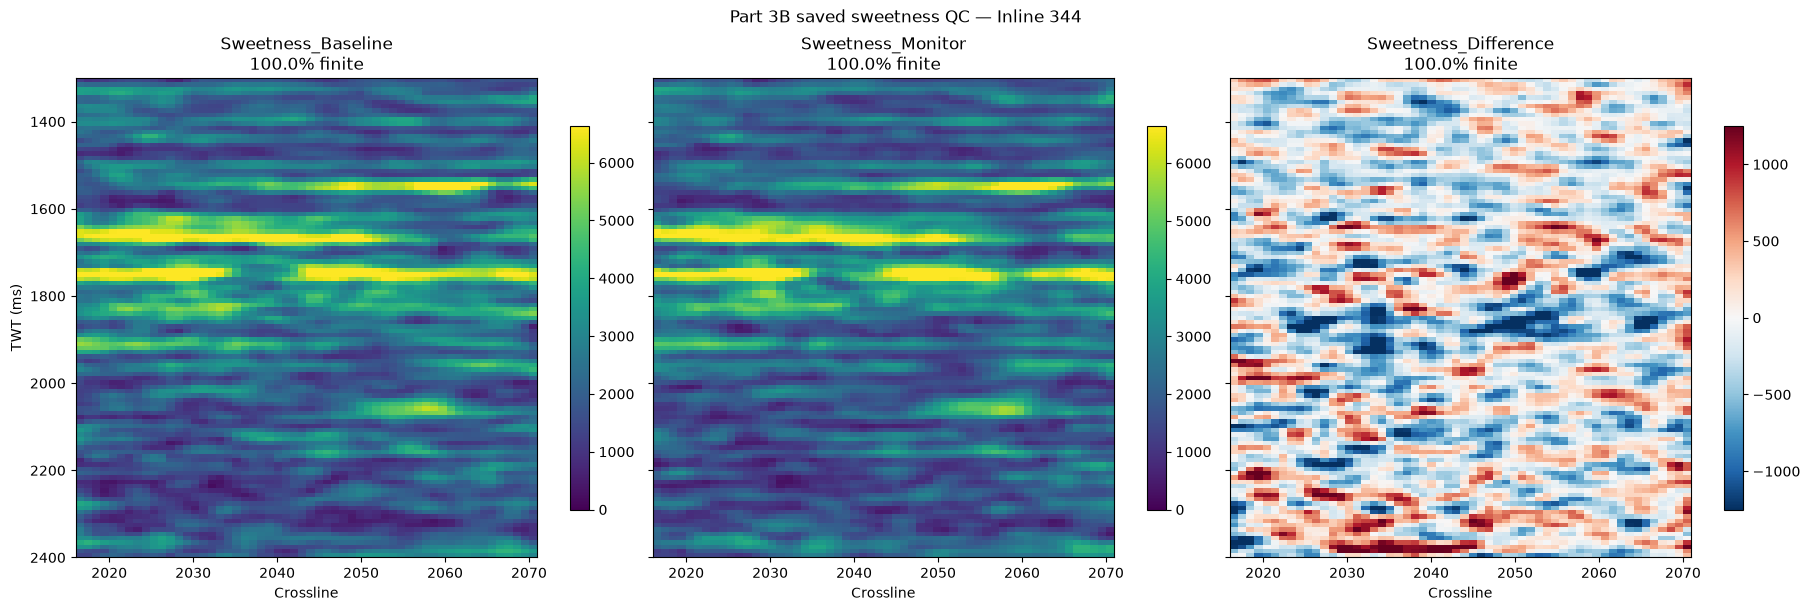

If no inline figure appears, open the saved PNG directly from the Jupyter file browser.


In [4]:
# CELL 4 — AUTOMATIC STATIC READ-BACK QC (NO WIDGETS REQUIRED)
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import segyio
from IPython.display import display, Image

OUT = Path('/data/epic20/APGCE/phase6_attributes/Attributes_10ms_50pct_overlap')
SGY = Path('/home/apgce_team_08/Phase6_Checkpoints/Baseline_Matched.sgy')
NAMES = ('Sweetness_Baseline', 'Sweetness_Monitor', 'Sweetness_Difference')
META = OUT / 'sweetness_metadata.json'
for p in [META, SGY, *(OUT / (name + '.npy') for name in NAMES)]:
    if not p.is_file():
        raise FileNotFoundError(f'Missing: {p}')

metadata = json.loads(META.read_text())
centers = np.asarray(metadata['centers_ms'], dtype=float)
vols = {name: np.load(OUT / (name + '.npy'), mmap_mode='r') for name in NAMES}
shape = vols[NAMES[0]].shape
assert all(v.shape == shape for v in vols.values()), 'Inconsistent saved attribute shapes'
assert len(centers) == shape[1], 'Metadata time axis mismatch'
print('SAVED SWEETNESS:', OUT)
print('Shape:', shape, '| time centers:', centers[0], 'to', centers[-1], 'ms')

# Sparse readback QC across the entire survey: never load complete 3D cubes.
rng = np.random.default_rng(42)
rows_qc = np.unique(rng.integers(0, shape[0], size=min(3000, shape[0])))
cols_qc = np.unique(np.linspace(0, shape[1]-1, min(100, shape[1]), dtype=int))
for name, vol in vols.items():
    a = np.asarray(vol[np.ix_(rows_qc, cols_qc)])
    finite = a[np.isfinite(a)]
    print(f'{name}: finite {100*finite.size/a.size:.2f}%',
          f'range [{np.min(finite):.5g}, {np.max(finite):.5g}]' if finite.size else 'NO FINITE VALUES')

# Read SEG-Y headers only; trace order is the same as the attribute .npy rows.
with segyio.open(str(SGY), 'r', ignore_geometry=True) as f:
    assert f.tracecount == shape[0], 'SEG-Y/attribute trace count mismatch'
    il = np.asarray(f.attributes(segyio.TraceField.INLINE_3D)[:], dtype=np.int32)
    xl = np.asarray(f.attributes(segyio.TraceField.CROSSLINE_3D)[:], dtype=np.int32)

# User controls: set TARGET_INLINE to an integer for a specific inline.
TARGET_INLINE = None
TWT_MIN_MS = max(1300., float(centers[0]))
TWT_MAX_MS = min(2400., float(centers[-1]))
MAX_TRACES = 450
CLIP_PERCENTILE = 98
cols = np.flatnonzero((centers >= TWT_MIN_MS) & (centers <= TWT_MAX_MS))
if cols.size < 2:
    cols = np.arange(shape[1]); print('Requested TWT range unavailable; showing full time axis')

# Choose an inline with finite monitor values. Check up to 40 candidate inlines.
unique_il = np.unique(il)
if TARGET_INLINE is None:
    candidates = unique_il[np.unique(np.linspace(0, len(unique_il)-1, min(40,len(unique_il)), dtype=int))]
else:
    candidates = np.asarray([int(TARGET_INLINE)])
best = None
best_count = -1
for inline_id in candidates:
    rr = np.flatnonzero(il == inline_id)
    if not rr.size: continue
    rr = rr[np.argsort(xl[rr], kind='stable')]
    if rr.size > MAX_TRACES:
        rr = rr[np.linspace(0, rr.size-1, MAX_TRACES, dtype=int)]
    # Only a small time subset needed to locate a viable section.
    probe_cols = cols[::max(1,len(cols)//30)]
    probe = np.asarray(vols['Sweetness_Monitor'][np.ix_(rr, probe_cols)])
    count = int(np.isfinite(probe).sum())
    if count > best_count:
        best_count = count; best = (int(inline_id), rr)
    if count > probe.size * .75:
        break
if best is None:
    raise ValueError('No valid inline geometry found in SEG-Y headers')
inline_id, rr = best
print(f'Selected inline {inline_id}, {len(rr)} traces; monitor probe finite={best_count}')

panels = {name: np.asarray(vols[name][np.ix_(rr, cols)], dtype=np.float32) for name in NAMES}
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True, constrained_layout=True)
for ax, name in zip(axes, NAMES):
    a = panels[name]
    finite = a[np.isfinite(a)]
    if finite.size == 0:
        ax.text(.5,.5,'NO FINITE VALUES\nCheck Cell 3 output',ha='center',va='center',transform=ax.transAxes)
        ax.set_title(name)
        continue
    if name == 'Sweetness_Difference':
        vmax = max(float(np.percentile(np.abs(finite), CLIP_PERCENTILE)), 1e-9)
        vmin = -vmax; cmap = 'RdBu_r'
    else:
        vmin = 0.; vmax = max(float(np.percentile(finite, CLIP_PERCENTILE)), 1e-9)
        cmap = 'viridis'
    image = ax.imshow(np.ma.masked_invalid(a.T), origin='upper', aspect='auto',
        extent=[float(xl[rr][0]),float(xl[rr][-1]),float(centers[cols[-1]]),float(centers[cols[0]])],
        vmin=vmin,vmax=vmax,cmap=cmap,interpolation='nearest')
    fig.colorbar(image,ax=ax,shrink=.8)
    ax.set_title(f'{name}\n{100*finite.size/a.size:.1f}% finite')
    ax.set_xlabel('Crossline')
axes[0].set_ylabel('TWT (ms)')
fig.suptitle(f'Part 3B saved sweetness QC — Inline {inline_id}')
PNG = OUT / 'Sweetness_Readback_QC_Static.png'
fig.savefig(PNG,dpi=130,bbox_inches='tight')
print('QC PNG saved:', PNG)
display(fig)
plt.close(fig)
print('If no inline figure appears, open the saved PNG directly from the Jupyter file browser.')
